# Notebook 03: Experiment 3, a non-Gaussian world

Companion to the Experiment 3 subsection of the report.

Design: content uniform on $(-\sqrt{3}, \sqrt{3})$, style Laplace, all with unit variance; every coordinate receives additive Laplace noise with standard deviation $0.1$ for content (price $0.01$), $0.3$ for $s_1$ (price $0.09$) and $1$ for $s_2, \dots, s_5$ (price $1$); the paper's mixing network, encoder and InfoNCE objective; runs with $d = 5$ and $d = 6$ outputs; one seed; 10,000 updates. Besides the per-coordinate probe scores, the cell estimates the prices from sampled pairs and measures the linearity of the learned map $g \circ f$: held-out $R^2$ of a linear and of a kernel fit of the representation from the latents, whose difference is the "linearity gap" of the report. Outputs: the per-coordinate table, the linearity table and `extension_nongaussian/nongaussian_check.png`.

This is one of seven notebooks obtained by splitting the single working notebook `main_mlp_explained.ipynb` by experiment, following the experiments of the comprehensive-exam report on von Kügelgen et al. (NeurIPS 2021):

| Notebook | Report section |
|---|---|
| 00 | Implementation; reproduction of the paper's experiment at a reduced budget |
| 01 | Experiment 1: the spare seat |
| 02 | Experiment 2: content recovery under perturbation |
| 03 | Experiment 3: a non-Gaussian world |
| 04 | Experiment 4: what decides the finite-budget outcome |
| 05 | Experiment 5: nonlinear representations and invariant functions of style |
| A1 | Supplementary runs not used in the report |

Every notebook runs on its own, top to bottom: Part A repeats the shared setup cells of notebook 00 verbatim, Part B holds the experiment. Saved outputs are carried over from the working notebook wherever a cell's source is unchanged; cells whose source was adjusted have no saved outputs and say so. Training runs are cached as files under the experiment's results folder, so a cell can be rerun and resumes from what is already there; choose a persistent location for that folder on Colab.

Notes on this notebook: one edit relative to the working notebook. Its last version of this cell had `NG_S1_STD = 0.50` (price $0.25$, a later variant whose saved run gave $s_1 \approx 0.25$ with $d = 5$ and $\approx 0.94$ with $d = 6$). The report's Experiment 3 uses $0.30$ (price $0.09$), restored here; the saved outputs of that cell were therefore cleared, so run the cell to regenerate the table (two trainings at 10,000 updates). Runs are cached under `extension_nongaussian/`; the $d = 5$ run at these settings is also the 10,000-update point of the budget test in Experiment 4.


## Part A: shared setup (identical in every notebook)

The cells of this part define the paper's simulation: the latent world, the augmentation at the latent level, the frozen mixing network, the encoder and the contrastive objective. They are copied verbatim from notebook 00, where each step is explained. Run them first; Part B uses `cfg`, `device`, `Settings`, `make_world`, `make_mixing`, `make_encoder` and `contrastive_loss` from here. The demonstration setting is `independent_partial`; each experiment overrides what it changes through `replace(cfg, ...)`.


## 2. Setup and settings

Use a Python 3.10+ notebook kernel. If an import is missing, uncomment the installation line, run it, and restart the kernel if requested. PyTorch can use an available NVIDIA GPU or Apple Silicon GPU; CPU also works. Numerical results can differ across devices and software versions.

In [1]:
import copy
import math
import platform
import time
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import wishart
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.kernel_ridge import KernelRidge
from sklearn.metrics import r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

import torch
from torch import nn
from IPython.display import display

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelsize": 11, "axes.titlesize": 12, "font.size": 10,
})

versions = {
    "Python": platform.python_version(), "PyTorch": torch.__version__,
    "NumPy": np.__version__, "SciPy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
}
display(pd.Series(versions, name="Version").to_frame())

,Version
Python,3.13.15
PyTorch,2.11.0+cu130
NumPy,2.1.3
SciPy,1.16.3
scikit-learn,1.6.1


The four named scenarios correspond to the progression in §5.1. Start with `independent_partial`, then change one setting at a time and rerun from this cell.

| Scenario | Chance each style coordinate changes | Dependence within blocks | Style depends on content |
|---|---:|---|---|
| `independent_all` | 1.00 | No | No |
| `independent_partial` | 0.75 | No | No |
| `dependent_blocks` | 0.75 | Yes | No |
| `content_causes_style` | 0.75 | Yes | Yes |

`content_dim` and `style_dim` describe the simulated world. `representation_dim` describes the encoder's output. The standard setting makes the output dimension equal to the content dimension.

`steps` is the number of parameter updates. Every update uses fresh simulated data. `batch_size` controls both the number of positive pairs and the size of the independent negative pool. Each anchor is compared with every item in that pool.

In [2]:
SCENARIO = "independent_partial"

SCENARIOS = {
    "independent_all":      (1.00, False, False),
    "independent_partial":  (0.75, False, False),
    "dependent_blocks":     (0.75, True,  False),
    "content_causes_style": (0.75, True,  True),
}

@dataclass
class Settings:
    seed: int = 7                          # Controls randomness so a run can be repeated.
    content_dim: int = 5                   # Number of true content variables, unchanged across paired views.
    style_dim: int = 5                     # Number of true style variables, which may change across views.
    representation_dim: int = 5            # Number of encoder outputs; equals content_dim.
    style_change_prob: float = 0.75        # Probability that each style coordinate is selected for change ("Biased Coin")
    statistical_dependence: bool = False   # If True, allow correlations within content, style noise, and augmentation noise.
    content_dependent_style: bool = False  # If True, generate style as s = a + Bc + noise.
    marginal_std: float = 1.0              # Standard deviation of content and residual style noise when dependence is off.
    style_noise_std: float = 1.0           # Standard deviation of noise added to selected style coordinates when dependence is off.
    mixing_layers: int = 3                 # Number of linear layers in the fixed latent-to-observation network.
    condition_pool: int = 25000            # Number of random matrices used to estimate a conditioning threshold.
    condition_quantile: float = 0.001      # Set the threshold using roughly the best-conditioned 0.1% of those matrices.
    learning_rate: float = 1e-4            # Controls the size of the encoder's parameter updates during training.
    temperature: float = 1.0               # Scales distances in the contrastive loss; smaller values sharpen comparisons.
    batch_size: int = 1024                  # Positive pairs per update; also the number of independent negative examples.
    steps: int = 10000                      # Total number of encoder parameter updates.
    log_every: int = 200                   # Print training progress every this many updates.
    probe_train_size: int = 3000            # Examples used to fit evaluation models that predict latents from representations.
    probe_test_size: int = 5000            # Separate examples used to test those evaluation models.
    device: str = "auto"                   # Automatically choose CUDA, then MPS, then CPU; can also set one explicitly.

cfg = Settings()
(cfg.style_change_prob, cfg.statistical_dependence,
 cfg.content_dependent_style) = SCENARIOS[SCENARIO]

# Original script's training scale (not enabled for this demonstration):
# cfg.batch_size = 6144
# cfg.steps = 100001
# The original nonlinear evaluation fits probes on 5 * 4096 examples and
# evaluates on 10 fresh batches of 4096. Kernel regression at that size is costly.

assert min(cfg.content_dim, cfg.style_dim, cfg.representation_dim) >= 1
assert 0 <= cfg.style_change_prob <= 1
assert min(cfg.marginal_std, cfg.style_noise_std, cfg.temperature) > 0
assert cfg.steps > 0 and cfg.batch_size > 1

if cfg.device != "auto":
    device = torch.device(cfg.device)
elif torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

torch.manual_seed(cfg.seed)
torch.set_num_threads(2)  # Avoid oversubscribing CPU cores in small examples.
latent_dim = cfg.content_dim + cfg.style_dim
print(f"Scenario: {SCENARIO}; device: {device}")
display(pd.Series(asdict(cfg), name="Setting").to_frame())

Scenario: independent_partial; device: cuda


,Setting
seed,7
content_dim,5
style_dim,5
representation_dim,5
style_change_prob,0.75
statistical_dependence,False
content_dependent_style,False
marginal_std,1.0
style_noise_std,1.0
mixing_layers,3


## 3. Build the latent world

We first draw content, then draw style:
$
c\sim N(0,\Sigma_c),\qquad
s=a+Bc+\varepsilon_s,\qquad
\varepsilon_s\sim N(0,\Sigma_s),
$
with independent content and residual draws.

If `statistical_dependence=False`, the covariance matrices are diagonal. If it is `True`, we generate covariance matrices that allow coordinates within each block to be correlated. A Wishart draw is simply a convenient way to generate a positive definite covariance matrix.

If `content_dependent_style=False`, we set $(a=0)$ and $(B=0)$. Otherwise, $(a+Bc)$ makes the distribution of style depend on content. This implements the paper's example of content influencing style.

The covariance matrices and $(a,B)$ are drawn once and then kept fixed. We repeatedly sample new people or objects from this same artificial world.

In [3]:
def make_world(settings):
    """Create fixed parameters of the data distribution on the CPU."""
    rng = np.random.default_rng(settings.seed)
    nc, ns = settings.content_dim, settings.style_dim

    def covariance(dim, std):
        if settings.statistical_dependence:
            # Match the intended Wishart construction in the original experiment.
            matrix = np.atleast_2d(wishart.rvs(df=dim, scale=np.eye(dim), random_state=rng))
        else:
            matrix = (std ** 2) * np.eye(dim)
        return torch.tensor(matrix, dtype=torch.float64)

    Sigma_c = covariance(nc, settings.marginal_std)
    Sigma_s = covariance(ns, settings.marginal_std)
    Sigma_aug = covariance(ns, settings.style_noise_std)
    # As in upstream spaces.py, explicit covariances supersede the std arguments.
    a = torch.zeros(ns)
    B = torch.zeros(ns, nc)
    if settings.content_dependent_style:
        a = torch.tensor(rng.standard_normal(ns), dtype=torch.float32)
        B = torch.tensor(rng.standard_normal((ns, nc)), dtype=torch.float32)
    return {
        "L_c": torch.linalg.cholesky(Sigma_c).float(),
        "L_s": torch.linalg.cholesky(Sigma_s).float(),
        "L_aug": torch.linalg.cholesky(Sigma_aug).float(),
        "a": a, "B": B,
    }

world = make_world(cfg)

def sample_latents(size, generator):
    """Draw z=(c,s). Latent values are used by the simulator and evaluator."""
    c = torch.randn(size, cfg.content_dim, generator=generator) @ world["L_c"].T
    eps_s = torch.randn(size, cfg.style_dim, generator=generator) @ world["L_s"].T
    s = world["a"] + c @ world["B"].T + eps_s
    return torch.cat([c, s], dim=1)

display(pd.DataFrame({
    "block": ["content", "style residual", "augmentation noise"],
    "dimension": [cfg.content_dim, cfg.style_dim, cfg.style_dim],
    "covariance": ["L_c @ L_c.T", "L_s @ L_s.T", "L_aug @ L_aug.T"],
}))

,block,dimension,covariance
0,content,5,L_c @ L_c.T
1,style residual,5,L_s @ L_s.T
2,augmentation noise,5,L_aug @ L_aug.T


For each original example, choose which style coordinates change using independent Bernoulli draws:
$
M_j\sim\mathrm{Bernoulli}(p),\qquad
\widetilde s=s+M\odot\eta,\qquad
\eta\sim N(0,\Sigma_{\mathrm{aug}}).
$
The symbol $(\odot)$ means coordinatewise multiplication. Content is copied exactly. A style coordinate whose mask equals zero is also copied exactly. The selected subset \(A\) is the set of coordinates whose masks equal one.

We additionally generate independent examples for the negative pool. They come from the same original latent distribution; they are not paired with the anchors.

When $(p>0)$ and the noise covariance is positive definite, each style coordinate has a chance to vary locally. Setting $(p=0)$ removes this property and changes the identification problem.

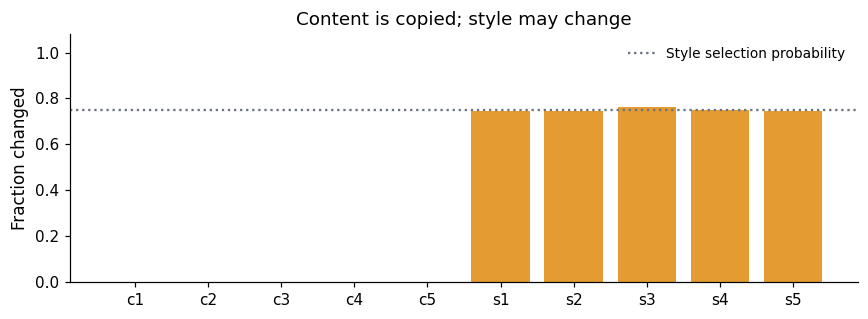

In [4]:
def augment_latents(z, generator):
    nc = cfg.content_dim
    style = z[:, nc:]
    mask = (torch.rand(style.shape, generator=generator) < cfg.style_change_prob)
    noise = torch.randn(style.shape, generator=generator) @ world["L_aug"].T
    changed_style = style + mask * noise
    return torch.cat([z[:, :nc], changed_style], dim=1)

def sample_triplet(size, generator):
    z = sample_latents(size, generator)
    z_negative = sample_latents(size, generator)
    z_augmented = augment_latents(z, generator)
    return z, z_augmented, z_negative

# A separate random stream keeps this inspection from changing training data.
inspection_rng = torch.Generator().manual_seed(cfg.seed + 10)
z_check, z_aug_check, _ = sample_triplet(5000, inspection_rng)
assert torch.equal(z_check[:, :cfg.content_dim], z_aug_check[:, :cfg.content_dim])
change_rates = (z_check != z_aug_check).float().mean(dim=0).numpy()
names = ([f"c{i+1}" for i in range(cfg.content_dim)] +
         [f"s{i+1}" for i in range(cfg.style_dim)])

fig, ax = plt.subplots(figsize=(8, 3))
colors = ["#227c9d"] * cfg.content_dim + ["#e49b32"] * cfg.style_dim
ax.bar(names, change_rates, color=colors)
ax.axhline(cfg.style_change_prob, color="#6b7280", linestyle=":", label="Style selection probability")
ax.set(ylim=(0, 1.08), ylabel="Fraction changed", title="Content is copied; style may change")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## 4. Hide the latents behind a fixed mixing network

The mixing network converts $(z)$ into $(x)$. It has square, invertible weight matrices and LeakyReLU activations with a nonzero negative slope. Its input and output both have dimension $(n_c+n_s)$, as in this particular synthetic experiment.

The condition number measures how unevenly a matrix stretches different directions. The code samples candidate matrices and keeps well-conditioned ones. This reduces severe numerical distortion; it is not a training step.

The mixing parameters are frozen. Only the encoder will be trained. LeakyReLU is invertible here but has a kink at zero, so this implementation is not literally smooth everywhere as required by the theorems.

In [5]:
def make_mixing(settings):
    """Adapt the upstream well-conditioned, square mixing MLP."""
    n = settings.content_dim + settings.style_dim
    rng = np.random.default_rng(settings.seed + 100)

    def candidate():
        matrix = rng.uniform(-1, 1, size=(n, n))
        return matrix / np.linalg.norm(matrix, axis=0, keepdims=True)

    conditions = np.array([
        np.linalg.cond(candidate()) for _ in range(settings.condition_pool)
    ])
    threshold = np.sort(conditions)[int(settings.condition_pool * settings.condition_quantile)]
    modules, accepted_conditions = [], []
    for layer in range(settings.mixing_layers):
        matrix = candidate()
        while np.linalg.cond(matrix) > threshold:
            matrix = candidate()
        linear = nn.Linear(n, n, bias=False)
        with torch.no_grad():
            linear.weight.copy_(torch.tensor(matrix, dtype=torch.float32))
        modules.append(linear)
        accepted_conditions.append(np.linalg.cond(matrix))
        if layer < settings.mixing_layers - 1:
            modules.append(nn.LeakyReLU(negative_slope=0.2))
    network = nn.Sequential(*modules).to(device)
    network.requires_grad_(False)
    network.eval()
    return network, accepted_conditions

mixing, condition_numbers = make_mixing(cfg)
print("Mixing layer condition numbers:", np.round(condition_numbers, 2))
print("Mixing parameters trainable:", any(p.requires_grad for p in mixing.parameters()))

with torch.no_grad():
    x_check = mixing(z_check[:5].to(device))
print("Latent shape:", tuple(z_check[:5].shape))
print("Observation shape:", tuple(x_check.shape))

Mixing layer condition numbers: [4.56 4.26 4.91]
Mixing parameters trainable: False
Latent shape: (5, 10)
Observation shape: (5, 10)


The encoder receives the mixed observation and outputs \(k\) numbers, where `representation_dim = k`. We preserve the original script's hidden-layer widths and activations.

With the default dimensions, the learned mapping is $(g:\mathbb R^{10}\to\mathbb R^5)$. It cannot invert the full observation. The desired result is an invertible representation of the five-dimensional content block after discarding additional style variation.

In [6]:
def make_encoder(settings):
    n = settings.content_dim + settings.style_dim
    # Same hidden widths as main_mlp.py; final layer has no activation.
    widths = [n, n * 10, n * 50, n * 50, n * 50, n * 50, n * 10,
              settings.representation_dim]
    modules = []
    for i, (n_in, n_out) in enumerate(zip(widths[:-1], widths[1:])):
        modules.append(nn.Linear(n_in, n_out))
        if i < len(widths) - 2:
            modules.append(nn.LeakyReLU(negative_slope=0.01))
    return nn.Sequential(*modules).to(device)

torch.manual_seed(cfg.seed + 200)
encoder = make_encoder(cfg)
initial_encoder = copy.deepcopy(encoder).eval()
print(encoder)
print("Trainable encoder parameters:", sum(p.numel() for p in encoder.parameters()))

Sequential(
  (0): Linear(in_features=10, out_features=100, bias=True)
  (1): LeakyReLU(negative_slope=0.01)
  (2): Linear(in_features=100, out_features=500, bias=True)
  (3): LeakyReLU(negative_slope=0.01)
  (4): Linear(in_features=500, out_features=500, bias=True)
  (5): LeakyReLU(negative_slope=0.01)
  (6): Linear(in_features=500, out_features=500, bias=True)
  (7): LeakyReLU(negative_slope=0.01)
  (8): Linear(in_features=500, out_features=500, bias=True)
  (9): LeakyReLU(negative_slope=0.01)
  (10): Linear(in_features=500, out_features=100, bias=True)
  (11): LeakyReLU(negative_slope=0.01)
  (12): Linear(in_features=100, out_features=5, bias=True)
)
Trainable encoder parameters: 853705


## 5. The contrastive objective

Let $(u_i=g(x_i))$, $(v_i=g(\widetilde x_i))$, and $(w_j=g(x_j^-))$. The first two form a positive pair. The $(w_j)$'s are encoded observations from the independent negative pool.

For the original loss's default settings, define
$
d_i^+=\|u_i-v_i\|^2,\qquad d_{ij}^-=\|u_i-w_j\|^2.
$
With batch size $(m)$ and temperature $(\tau)$, the loss is
$
\frac1m\sum_i\left[
\frac{d_i^+}{\tau}
+\log\left\{\frac{e^{-d_i^+/\tau}+\sum_{j=1}^m e^{-d_{ij}^-/\tau}}{m+1}\right\}
\right].
$

The first term encourages paired representations to agree. The second makes mapping everything to the same point unattractive: independent examples can instead be separated while positive pairs remain close. Both effects depend on the same learned representation.

This is the squared-distance, InfoNCE-style objective used in the synthetic script. The denominator uses a mean rather than a sum, changing the loss by a constant for fixed batch size. Negative loss values are therefore normal.

We do not calculate differential entropy directly. Theorem 4.4 studies exact population alignment plus entropy on a bounded output domain; this code uses a finite batch contrastive surrogate and unconstrained outputs. Its numerical behavior is evidence about the method, not a direct execution of that theorem's assumptions.

In [7]:
def contrastive_loss(anchor, positive, negative, temperature=1.0):
    """Same objective as LpSimCLRLoss at its default p=2, alpha=0.5."""
    positive_distance = (anchor - positive).square().sum(dim=1)
    # Algebraically equal to all pairwise squared differences, using less memory.
    negative_distance = (
        anchor.square().sum(dim=1, keepdim=True)
        + negative.square().sum(dim=1).unsqueeze(0)
        - 2 * anchor @ negative.T
    ).clamp_min(0)
    all_distances = torch.cat([negative_distance, positive_distance[:, None]], dim=1)
    alignment = positive_distance / temperature
    contrast = torch.logsumexp(-all_distances / temperature, dim=1)
    contrast = contrast - math.log(all_distances.shape[1])
    loss = (alignment + contrast).mean()
    return loss, alignment.mean().detach(), contrast.mean().detach()

zero = torch.zeros(8, cfg.representation_dim, device=device)
collapsed_loss, _, _ = contrastive_loss(zero, zero, zero, cfg.temperature)
print(f"Loss of a constant representation: {collapsed_loss.item():.3f}")

Loss of a constant representation: 0.000


## Part B: Experiment 3


The cell defines the non-Gaussian samplers, the probes and `ng_run`, then runs $d = 5$ and $d = 6$ and reports the per-coordinate $R^2$, the linearity of $h = g \circ f$ and the coordinate-level probe gaps (kernel minus linear).


[nongaussian] empirical price per coordinate, r_l = Var(z_l~ - z_l) / Var(z_l):


,c1,c2,c3,c4,c5,s1,s2,s3,s4,s5
price,0.01,0.01,0.01,0.01,0.01,0.09,0.997,0.996,0.974,1.034


nongaussian_d5_c0.1_s10.3_h0_uniform_seed0_steps10000: 1/10000  loss -0.000  alignment  0.000
nongaussian_d5_c0.1_s10.3_h0_uniform_seed0_steps10000: 200/10000  loss -1.967  alignment  1.019
nongaussian_d5_c0.1_s10.3_h0_uniform_seed0_steps10000: 400/10000  loss -3.022  alignment  1.425
nongaussian_d5_c0.1_s10.3_h0_uniform_seed0_steps10000: 600/10000  loss -3.354  alignment  1.332
nongaussian_d5_c0.1_s10.3_h0_uniform_seed0_steps10000: 800/10000  loss -3.561  alignment  1.457
nongaussian_d5_c0.1_s10.3_h0_uniform_seed0_steps10000: 1000/10000  loss -4.096  alignment  1.804
nongaussian_d5_c0.1_s10.3_h0_uniform_seed0_steps10000: 1200/10000  loss -4.348  alignment  1.827
nongaussian_d5_c0.1_s10.3_h0_uniform_seed0_steps10000: 1400/10000  loss -4.555  alignment  1.874
nongaussian_d5_c0.1_s10.3_h0_uniform_seed0_steps10000: 1600/10000  loss -4.697  alignment  1.838
nongaussian_d5_c0.1_s10.3_h0_uniform_seed0_steps10000: 1800/10000  loss -4.775  alignment  1.768
nongaussian_d5_c0.1_s10.3_h0_uniform_

c1    c2    c3    c4    c5    s1    s2    s3    s4  \
world       rep_dim                                                         
nongaussian 5        0.90  0.93  0.96  0.87  0.89  0.57 -0.01 -0.01 -0.01   
            6        0.98  0.98  0.98  0.97  0.97  0.94  0.00  0.01  0.00   

                       s5  
world       rep_dim        
nongaussian 5       -0.01  
            6        0.00

Per-factor R²: mean and standard deviation across seeds


nonlin_c1       nonlin_c2       nonlin_c3       nonlin_c4  \
                         mean   std      mean   std      mean   std      mean   
world       rep_dim                                                             
nongaussian 5            0.90  0.08      0.93  0.04      0.96  0.03      0.87   
            6            0.98  0.00      0.98  0.01      0.98  0.01      0.97   

                          nonlin_c5       nonlin_s1       nonlin_s2        \
                      std      mean   std      mean   std      mean   std   
world       rep_dim                                                         
nongaussian 5        0.10      0.89  0.09      0.57  0.26     -0.01  0.01   
            6        0.02      0.97  0.01      0.94  0.04      0.00  0.01   

                    nonlin_s3      nonlin_s4       nonlin_s5        
                         mean  std      mean   std      mean   std  
world       rep_dim                                                 
nongaussian 5           -0.01  0.0     -0.01  0.00     -0.01  0.01  
            6            0.01  0.0      0.00  0.01      0.00  0.00

How linear is the learned map? (gaps near 0 = near-linear; large gaps = nonlinear)


h: linear R²  h: kernel R²  h gap (kernel - linear)  \
world       rep_dim                                                        
nongaussian 5               0.984         0.992                    0.008   
            6               0.979         0.990                    0.010   

                     content probe gap  style probe gap  
world       rep_dim                                      
nongaussian 5                    0.028            0.013  
            6                    0.010            0.002

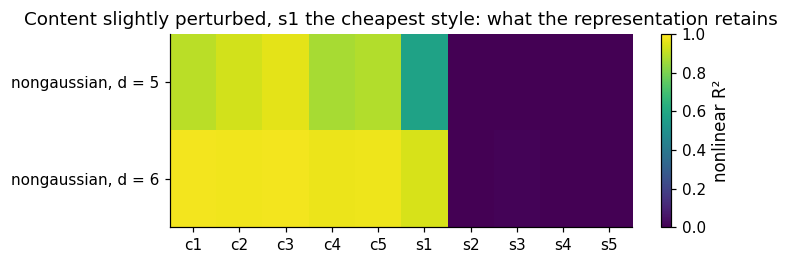

Saved results to: /content/extension_nongaussian


In [8]:
# =============================================================================
# Non-Gaussian, nonlinear check: uniform content, Laplace style, Laplace changes,
# the paper's nonlinear mixing + MLP encoder + InfoNCE. Runs: d = 5 and d = 6.
# Also reports how linear the learned map h: z -> representation turned out to be.
# Optionally repeats everything in a Gaussian world for a side-by-side reference.
# Requires the notebook definitions: cfg, device, make_mixing, make_encoder,
# contrastive_loss, and the imports. Runs are cached in NG_DIR.
# =============================================================================
import json
from dataclasses import replace

# ------------------------------- knobs ---------------------------------------
NG_WORLDS = ["nongaussian"]     # add "gaussian" to run the same pipeline with Gaussian latents/noise
NG_CONTENT_STD = 0.10           # content change std as a fraction of spread (price 0.01)
NG_S1_STD = 0.30                # change std of the designated "winning" style coordinate (price 0.09)
NG_OTHER_STD = 1.00             # change std of s2..s5 (price 1)
NG_HETERO = 0.0                 # 0 = constant noise scale; 0.5 = scale (1 + 0.5|z|), value-dependent
NG_CONTENT_MARGINAL = "uniform" # "uniform" or "laplace" content marginal in the non-Gaussian world
NG_SEEDS = [0,1,2]
NG_STEPS = cfg.steps
NG_DIR = Path("extension_nongaussian")
NG_DIR.mkdir(parents=True, exist_ok=True)

NC, NS, N = cfg.content_dim, cfg.style_dim, cfg.content_dim + cfg.style_dim
COORDS = [f"c{i+1}" for i in range(NC)] + [f"s{i+1}" for i in range(NS)]
base_ng = replace(cfg, style_change_prob=1.0, statistical_dependence=False,
                  content_dependent_style=False, steps=NG_STEPS)


# ------------------------------- samplers ------------------------------------
def laplace(shape, gen, std):
    """Laplace noise with the requested std, as the difference of two exponentials.
    Var(Laplace(b)) = 2 b^2, so b = std / sqrt(2). rand is in [0, 1), so 1 - rand is in
    (0, 1] and log1p(-rand) never sees zero (the earlier inverse-CDF version could)."""
    b = std / np.sqrt(2.0)
    e1 = -torch.log1p(-torch.rand(shape, generator=gen))
    e2 = -torch.log1p(-torch.rand(shape, generator=gen))
    return b * (e1 - e2)


def ng_noise(shape, gen, std, world):
    if world == "gaussian":
        return torch.randn(shape, generator=gen) * std
    return laplace(shape, gen, std)


def ng_draw_z(size, gen, world):
    """Latents with unit variance. Gaussian world: all N(0,1). Non-Gaussian world: content
    uniform on (-sqrt3, sqrt3) or Laplace, style Laplace."""
    if world == "gaussian":
        return torch.randn(size, N, generator=gen)
    if NG_CONTENT_MARGINAL == "laplace":
        c = laplace((size, NC), gen, 1.0)
    else:
        c = (torch.rand(size, NC, generator=gen) * 2 - 1) * np.sqrt(3.0)
    s = laplace((size, NS), gen, 1.0)
    return torch.cat([c, s], dim=1)


def ng_change_std():
    v = np.full(N, NG_OTHER_STD, dtype=np.float32)
    v[:NC] = NG_CONTENT_STD
    v[NC] = NG_S1_STD
    return torch.as_tensor(v)


def ng_perturb(z, gen, world):
    """Second view: every coordinate moves by noise of the chosen std (optionally value-dependent)."""
    scale = ng_change_std() * (1.0 + NG_HETERO * z.abs())
    return z + ng_noise(z.shape, gen, 1.0, world) * scale


def ng_triplet(size, gen, world):
    z = ng_draw_z(size, gen, world)
    z_neg = ng_draw_z(size, gen, world)
    return z, ng_perturb(z, gen, world), z_neg


def ng_prices(world, n=50000):
    z, z_aug, _ = ng_triplet(n, torch.Generator().manual_seed(12345), world)
    return ((z_aug - z).var(dim=0) / z.var(dim=0)).numpy()


# ------------------------------- probes --------------------------------------
KRR_GRID = {"kernelridge__alpha": [1.0, 0.1, 0.01, 0.001],
            "kernelridge__gamma": [float(g) for g in np.logspace(-2, 2, 4)]}


def kernel_fit(X_tr, Y_tr):
    search = GridSearchCV(make_pipeline(StandardScaler(), KernelRidge(kernel="rbf")),
                          KRR_GRID, scoring="r2", cv=3, n_jobs=1)
    with threadpool_limits(limits=2):
        search.fit(X_tr, Y_tr)
    return search


def ng_probe(X_tr, Y_tr, X_te, Y_te):
    """Latents from the representation: held-out R^2 per coordinate, linear and kernel probes."""
    lin = make_pipeline(StandardScaler(), LinearRegression()).fit(X_tr, Y_tr)
    lin_r2 = r2_score(Y_te, lin.predict(X_te), multioutput="raw_values")
    pred = np.zeros_like(Y_te)
    for cols in (slice(0, NC), slice(NC, None)):
        pred[:, cols] = kernel_fit(X_tr, Y_tr[:, cols]).predict(X_te)
    return lin_r2, r2_score(Y_te, pred, multioutput="raw_values")


def linearity_of_h(X, Z):
    """How linear is the learned map h: z -> representation?

    Fit the representation X from the latents Z with a linear model and with a kernel
    model on half the data, score on the other half. Returns per-output R^2 for both.
    A small gap (kernel - linear) means h is close to linear; a large gap means it is not.
    This is the forward direction, h itself, unlike the probes, which fit its inverse.
    """
    n = len(Z) // 2
    lin = make_pipeline(StandardScaler(), LinearRegression()).fit(Z[:n], X[:n])
    lin_r2 = r2_score(X[n:], lin.predict(Z[n:]), multioutput="raw_values")
    ker_r2 = r2_score(X[n:], kernel_fit(Z[:n], X[:n]).predict(Z[n:]), multioutput="raw_values")
    return lin_r2, ker_r2


# ------------------------------- one run --------------------------------------
def ng_run(world, rep_dim, seed):
    settings = replace(base_ng, seed=seed, representation_dim=rep_dim)
    tag = (f"{world}_d{rep_dim}_c{NG_CONTENT_STD:g}_s1{NG_S1_STD:g}_h{NG_HETERO:g}"
           f"_{NG_CONTENT_MARGINAL}_seed{seed}_steps{settings.steps}")
    path = NG_DIR / f"{tag}.json"
    if path.exists():
        return json.loads(path.read_text())

    mix, _ = make_mixing(settings)                 # paper's random nonlinear invertible mixing
    torch.manual_seed(settings.seed + 200)
    net = make_encoder(settings)                   # paper's nonlinear MLP with rep_dim outputs
    opt = torch.optim.Adam(net.parameters(), lr=settings.learning_rate)
    gen = torch.Generator().manual_seed(settings.seed + 300)

    net.train()
    t0 = time.perf_counter()
    for step in range(1, settings.steps + 1):
        z, z_aug, z_neg = ng_triplet(settings.batch_size, gen, world)
        with torch.no_grad():
            x, x_aug, x_neg = (mix(v.to(device)) for v in (z, z_aug, z_neg))
        opt.zero_grad(set_to_none=True)
        loss, alignment, _ = contrastive_loss(net(x), net(x_aug), net(x_neg), settings.temperature)
        if not torch.isfinite(loss):
            raise RuntimeError(f"Nonfinite loss in {tag} at step {step}")
        loss.backward()
        opt.step()
        if step == 1 or step % settings.log_every == 0 or step == settings.steps:
            print(f"{tag}: {step}/{settings.steps}  loss {loss.item(): .3f}  alignment {alignment.item(): .3f}")
    net.eval()

    @torch.no_grad()
    def encode(z):
        return torch.cat([net(mix(chunk.to(device))).cpu() for chunk in z.split(512)]).numpy().astype(np.float64)

    z_tr = ng_draw_z(settings.probe_train_size, torch.Generator().manual_seed(seed + 400), world)
    z_te = ng_draw_z(settings.probe_test_size, torch.Generator().manual_seed(seed + 500), world)
    X_tr, X_te = encode(z_tr), encode(z_te)
    Z_tr, Z_te = z_tr.numpy().astype(np.float64), z_te.numpy().astype(np.float64)

    lin, nonlin = ng_probe(X_tr, Z_tr, X_te, Z_te)          # latents from representation
    h_lin, h_ker = linearity_of_h(X_te, Z_te)                # representation from latents

    result = {"world": world, "rep_dim": rep_dim, "seed": seed, "steps": settings.steps,
              "seconds": time.perf_counter() - t0,
              "h_linear_r2": float(h_lin.mean()), "h_kernel_r2": float(h_ker.mean()),
              "h_gap": float(h_ker.mean() - h_lin.mean())}
    result.update({f"h_lin_out{i+1}": float(v) for i, v in enumerate(h_lin)})
    result.update({f"h_ker_out{i+1}": float(v) for i, v in enumerate(h_ker)})
    result.update({f"nonlin_{n}": float(v) for n, v in zip(COORDS, nonlin)})
    result.update({f"lin_{n}": float(v) for n, v in zip(COORDS, lin)})
    path.write_text(json.dumps(result, indent=2))
    return result


# ------------------------------- run & report --------------------------------
for world in NG_WORLDS:
    print(f"[{world}] empirical price per coordinate, r_l = Var(z_l~ - z_l) / Var(z_l):")
    display(pd.DataFrame([ng_prices(world)], columns=COORDS, index=["price"]).round(3))

ng = pd.DataFrame([ng_run(w, d, s) for w in NG_WORLDS for d in (NC, NC + 1) for s in NG_SEEDS])
ng.to_csv(NG_DIR / "results.csv", index=False)

nonlin_cols = [f"nonlin_{n}" for n in COORDS]
table = (ng.groupby(["world", "rep_dim"])[nonlin_cols].mean()
           .rename(columns=lambda c: c.replace("nonlin_", "")))
print("Held-out nonlinear R² per latent coordinate (mean over seeds); rows = (world, output dim):")
display(table.round(2))
# ADDED: mean and sample standard deviation across seeds
summary = (
    ng.groupby(["world", "rep_dim"])[nonlin_cols]
      .agg(["mean", "std"])
)
print("Per-factor R²: mean and standard deviation across seeds")
display(summary.round(2))
# Linearity of the learned map h, plus the coordinate-level probe gap (kernel - linear).
lin_cols = [f"lin_{n}" for n in COORDS]
gap = pd.DataFrame({
    "h: linear R²": ng.groupby(["world", "rep_dim"])["h_linear_r2"].mean(),
    "h: kernel R²": ng.groupby(["world", "rep_dim"])["h_kernel_r2"].mean(),
    "h gap (kernel - linear)": ng.groupby(["world", "rep_dim"])["h_gap"].mean(),
    "content probe gap": (ng.groupby(["world", "rep_dim"])[nonlin_cols[:NC]].mean().mean(axis=1)
                          - ng.groupby(["world", "rep_dim"])[lin_cols[:NC]].mean().mean(axis=1)),
    "style probe gap": (ng.groupby(["world", "rep_dim"])[nonlin_cols[NC:]].mean().mean(axis=1)
                        - ng.groupby(["world", "rep_dim"])[lin_cols[NC:]].mean().mean(axis=1)),
})
print("How linear is the learned map? (gaps near 0 = near-linear; large gaps = nonlinear)")
display(gap.round(3))

fig, ax = plt.subplots(figsize=(7, 0.9 + 0.8 * len(table)))
im = ax.imshow(table.values, aspect="auto", vmin=0, vmax=1, cmap="viridis")
ax.set(xticks=range(N), xticklabels=COORDS, yticks=range(len(table)),
       yticklabels=[f"{w}, d = {d}" for w, d in table.index],
       title="Content slightly perturbed, s1 the cheapest style: what the representation retains")
fig.colorbar(im, ax=ax, label="nonlinear R²")
fig.tight_layout()
fig.savefig(NG_DIR / "nongaussian_check.png", dpi=150)
plt.show()
print("Saved results to:", NG_DIR.resolve())